In [16]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lava18/google-play-store-apps/googleplaystore.csv
/kaggle/input/datasets/lava18/google-play-store-apps/license.txt
/kaggle/input/datasets/lava18/google-play-store-apps/googleplaystore_user_reviews.csv


In [17]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Load Google Play Store app data
apps = pd.read_csv("/kaggle/input/datasets/lava18/google-play-store-apps/googleplaystore.csv")

print("Google Play Store Apps Dataset:", apps.shape)

Google Play Store Apps Dataset: (10841, 13)


In [19]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide Apps",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [20]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [21]:
apps.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [22]:
apps.describe()


,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [23]:
apps.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [24]:
apps.duplicated().sum()

np.int64(483)

In [25]:
apps[apps["Type"].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [26]:
apps[apps["Content Rating"].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [27]:
apps["Rating"].describe()

count    9367.000000
mean        4.193338
std         0.537431
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64

In [28]:
apps["Rating"].isnull().sum() / len(apps) * 100

np.float64(13.596531685268886)

In [29]:
print("Reviews:")
print(apps["Reviews"].head(10).tolist())

print("\nSize:")
print(apps["Size"].unique()[:15])

print("\nInstalls:")
print(apps["Installs"].unique()[:15])

print("\nPrice:")
print(apps["Price"].unique()[:15])

Reviews:
['159', '967', '87510', '215644', '967', '167', '178', '36815', '13791', '121']

Size:
['19M' '14M' '8.7M' '25M' '2.8M' '5.6M' '29M' '33M' '3.1M' '28M' '12M'
 '20M' '21M' '37M' '2.7M']

Installs:
['10,000+' '500,000+' '5,000,000+' '50,000,000+' '100,000+' '50,000+'
 '1,000,000+' '10,000,000+' '5,000+' '100,000,000+' '1,000,000,000+'
 '1,000+' '500,000,000+' '50+' '100+']

Price:
['0' '$4.99' '$3.99' '$6.99' '$1.49' '$2.99' '$7.99' '$5.99' '$3.49'
 '$1.99' '$9.99' '$7.49' '$0.99' '$9.00' '$5.49']


In [30]:
apps[apps.duplicated(keep=False)].sort_values("App").head(20)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
1393,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
1407,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
2543,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2322,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2256,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
2385,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
7035,420 BZ Budeze Delivery,MEDICAL,5.0,2,11M,100+,Free,0,Mature 17+,Medical,"June 6, 2018",1.0.1,4.1 and up
2522,420 BZ Budeze Delivery,MEDICAL,5.0,2,11M,100+,Free,0,Mature 17+,Medical,"June 6, 2018",1.0.1,4.1 and up


In [31]:
# Remove exact duplicate records
apps.drop_duplicates(inplace=True)

print("Dataset shape:", apps.shape)
print("Remaining duplicates:", apps.duplicated().sum())

Dataset shape: (10358, 13)
Remaining duplicates: 0


In [32]:
# Identify ratings outside the valid range
apps.loc[(apps["Rating"] < 1) | (apps["Rating"] > 5),["App", "Rating"]]

,App,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [33]:
apps.loc[(apps["Rating"] < 1) | (apps["Rating"] > 5),"Rating"] = np.nan

In [34]:
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")

In [35]:
def convert_size(size):
    if pd.isna(size) or size == "Varies with device":
        return np.nan

    elif size.endswith("M"):
        return float(size[:-1])

    elif size.endswith("k"):
        return float(size[:-1]) / 1024

    return np.nan


apps["Size"] = apps["Size"].apply(convert_size)

In [36]:
apps["Installs"] = (
    apps["Installs"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

apps["Installs"] = pd.to_numeric(
    apps["Installs"],
    errors="coerce"
)

In [37]:
apps["Price"] = (
    apps["Price"]
    .astype("string")
    .str.replace("$", "", regex=False)
)

apps["Price"] = pd.to_numeric(
    apps["Price"],
    errors="coerce"
)

In [38]:
apps["Last Updated"] = pd.to_datetime(
    apps["Last Updated"],
    errors="coerce"
)

In [39]:
apps.isnull().sum()

App                  0
Category             0
Rating            1466
Reviews              1
Size              1527
Installs             1
Type                 1
Price                1
Content Rating       1
Genres               0
Last Updated         1
Current Ver          8
Android Ver          3
dtype: int64

In [40]:
missing_summary = pd.DataFrame({
    "Missing Values": apps.isnull().sum(),
    "Missing Percentage": (
        apps.isnull().mean() * 100
    ).round(2)
})

missing_summary.sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
Size,1527,14.74
Rating,1466,14.15
Current Ver,8,0.08
Android Ver,3,0.03
Reviews,1,0.01
Content Rating,1,0.01
Price,1,0.01
Installs,1,0.01
Type,1,0.01
Last Updated,1,0.01


In [41]:
apps["Size"].dtype

dtype('float64')

In [42]:
apps["Size"].notna().sum()

np.int64(8831)

In [43]:
apps.drop(index=10472, inplace=True)

print("Dataset shape:", apps.shape)

Dataset shape: (10357, 13)


In [44]:
apps.isnull().sum()

App                  0
Category             0
Rating            1465
Reviews              0
Size              1526
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [45]:
text_columns = ["App",
    "Category",
    "Type",
    "Content Rating",
    "Genres",
    "Current Ver",
    "Android Ver"]

for col in text_columns:
    apps[col] = apps[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

In [46]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10357 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10357 non-null  object        
 1   Category        10357 non-null  object        
 2   Rating          8892 non-null   float64       
 3   Reviews         10357 non-null  float64       
 4   Size            8831 non-null   float64       
 5   Installs        10357 non-null  Int64         
 6   Type            10356 non-null  object        
 7   Price           10357 non-null  Float64       
 8   Content Rating  10357 non-null  object        
 9   Genres          10357 non-null  object        
 10  Last Updated    10357 non-null  datetime64[ns]
 11  Current Ver     10349 non-null  object        
 12  Android Ver     10355 non-null  object        
dtypes: Float64(1), Int64(1), datetime64[ns](1), float64(3), object(7)
memory usage: 1.1+ MB


In [47]:
print("Duplicate rows:", apps.duplicated().sum())

Duplicate rows: 0


In [48]:
print("Minimum rating:", apps["Rating"].min())
print("Maximum rating:", apps["Rating"].max())

Minimum rating: 1.0
Maximum rating: 5.0


In [49]:
apps.describe()

,Rating,Reviews,Size,Installs,Price,Last Updated
count,8892.000000,1.035700e+04,8831.000000,10357.0,10357.0,10357
mean,4.187877,4.059046e+05,21.287413,14157759.440668,1.0308,2017-11-14 09:25:19.320266496
min,1.000000,0.000000e+00,0.008301,0.0,0.0,2010-05-21 00:00:00
25%,4.000000,3.200000e+01,4.700000,1000.0,0.0,2017-09-03 00:00:00
50%,4.300000,1.680000e+03,13.000000,100000.0,0.0,2018-05-20 00:00:00
75%,4.500000,4.641600e+04,29.000000,1000000.0,0.0,2018-07-19 00:00:00
max,5.000000,7.815831e+07,100.000000,1000000000.0,400.0,2018-08-08 00:00:00
std,0.522377,2.696778e+06,22.540591,80239553.869019,16.278625,NaN


In [50]:
#Average Rating of Apps
average_rating = apps["Rating"].mean()

print("Average App Rating:", round(average_rating, 2))

Average App Rating: 4.19


In [51]:
#Number of Unique Categories
unique_categories = apps["Category"].nunique()

print("Number of unique categories:", unique_categories)

Number of unique categories: 33


In [52]:
apps["Size"].describe()

count    8831.000000
mean       21.287413
std        22.540591
min         0.008301
25%         4.700000
50%        13.000000
75%        29.000000
max       100.000000
Name: Size, dtype: float64

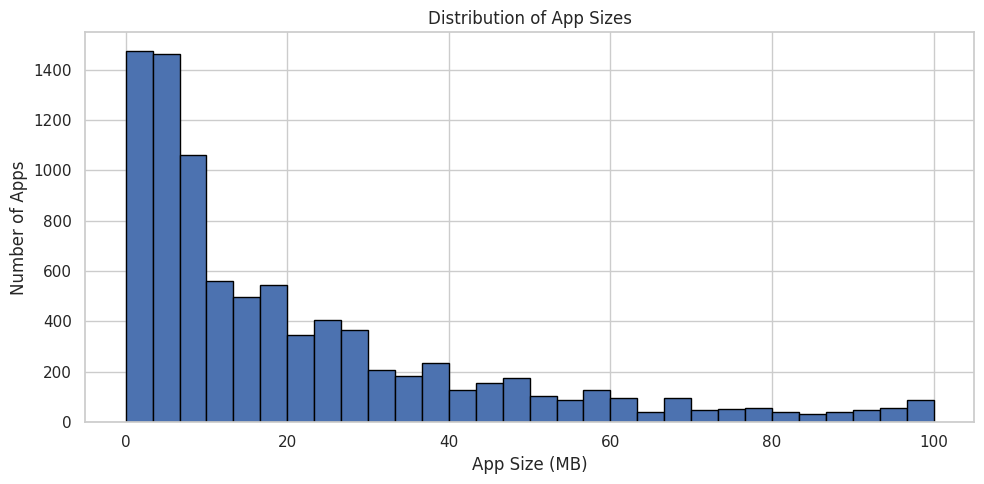

In [53]:
#distribution of app sizes
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
apps["Size"].dropna().hist(bins=30, edgecolor="black")

plt.title("Distribution of App Sizes")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

In [54]:
#How many apps are free, and how many are paid?
apps["Type"].value_counts()

Type
Free    9591
Paid     765
Name: count, dtype: int64

In [55]:
type_counts = apps["Type"].value_counts()

type_percentages = apps["Type"].value_counts(normalize=True).mul(100).round(2)

print("App Counts:")
print(type_counts)

print("\nApp Percentages:")
print(type_percentages)

App Counts:
Type
Free    9591
Paid     765
Name: count, dtype: int64

App Percentages:
Type
Free    92.61
Paid     7.39
Name: proportion, dtype: float64


In [56]:
#Most common content rating
apps["Content Rating"].value_counts()

Content Rating
Everyone           8382
Teen               1146
Mature 17+          447
Everyone 10+        377
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

In [57]:
print("Total rows:", len(apps))
print("Unique app names:", apps["App"].nunique())
print("Rows with repeated app names:", apps["App"].duplicated().sum())

Total rows: 10357
Unique app names: 9659
Rows with repeated app names: 698


In [58]:
#top 5 apps by number of installs?
unique_apps = (
    apps.sort_values(["Installs", "Reviews"],
        ascending=[False, False])
    .drop_duplicates(subset="App", keep="first")
)

top_5_installed = unique_apps.nlargest(5, "Installs")[
    ["App", "Category", "Installs", "Rating"]
]

top_5_installed

,App,Category,Installs,Rating
2544,Facebook,SOCIAL,1000000000,4.1
336,WhatsApp Messenger,COMMUNICATION,1000000000,4.4
2604,Instagram,SOCIAL,1000000000,4.5
382,Messenger – Text and Video Chat for Free,COMMUNICATION,1000000000,4.0
1872,Subway Surfers,GAME,1000000000,4.5


In [59]:
#Apps having 4+ rating
high_rated_count = apps[apps["Rating"] >= 4.0].shape[0]

print("Apps with Rating >= 4.0:", high_rated_count)

Apps with Rating >= 4.0: 6947


In [60]:
average_reviews_by_type = apps.groupby("Type")["Reviews"].mean()

print(average_reviews_by_type.round(2))

Type
Free    437373.59
Paid     11900.55
Name: Reviews, dtype: float64


In [61]:
#average number of reviews for free vs. paid apps?
review_comparison = (apps.groupby("Type")["Reviews"].mean().reset_index())

review_comparison.columns = ["App Type", "Average Reviews"]

review_comparison["Average Reviews"] = (review_comparison["Average Reviews"].round(2))

review_comparison

,App Type,Average Reviews
0,Free,437373.59
1,Paid,11900.55


In [62]:
#average app size for each category?
average_size_by_category = (apps.groupby("Category")["Size"]
    .mean()
    .sort_values(ascending=False)
    .round(2))

print(average_size_by_category)

Category
GAME                   44.13
FAMILY                 27.93
TRAVEL_AND_LOCAL       24.52
SPORTS                 24.18
ENTERTAINMENT          22.64
PARENTING              22.51
FOOD_AND_DRINK         22.06
HEALTH_AND_FITNESS     21.64
EDUCATION              20.08
AUTO_AND_VEHICLES      20.04
MEDICAL                19.38
FINANCE                17.94
SOCIAL                 16.88
PHOTOGRAPHY            16.83
MAPS_AND_NAVIGATION    16.61
VIDEO_PLAYERS          16.08
HOUSE_AND_HOME         15.97
SHOPPING               15.90
DATING                 15.83
LIFESTYLE              14.86
EVENTS                 13.96
BUSINESS               13.91
BEAUTY                 13.80
COMICS                 13.48
BOOKS_AND_REFERENCE    13.19
WEATHER                13.12
PRODUCTIVITY           12.87
NEWS_AND_MAGAZINES     12.65
ART_AND_DESIGN         12.37
COMMUNICATION          11.66
PERSONALIZATION        11.29
LIBRARIES_AND_DEMO     11.08
TOOLS                   8.77
Name: Size, dtype: float64


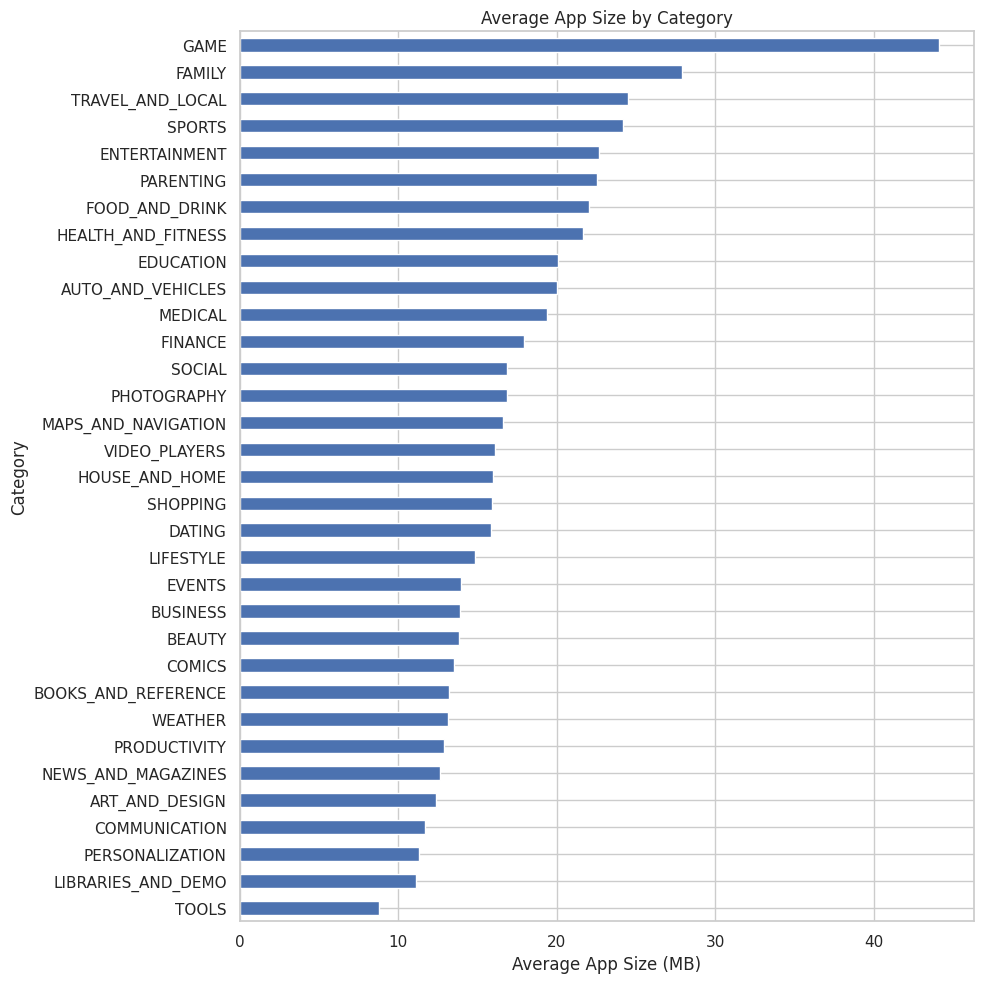

In [63]:
average_size_by_category.sort_values().plot(kind="barh",
    figsize=(10, 10),
    title="Average App Size by Category")

plt.xlabel("Average App Size (MB)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [64]:
#apps that were last updated in 2018?
apps_updated_2018 = (apps["Last Updated"].dt.year == 2018).sum()

print("Apps Last Updated in 2018:", apps_updated_2018)

Apps Last Updated in 2018: 6934


In [65]:
#correlation between app ratings and the number of installs?
rating_install_corr = apps[["Rating", "Installs"]].corr().loc[
    "Rating", "Installs"]

print("Correlation between Rating and Installs:",
      round(rating_install_corr, 4))

Correlation between Rating and Installs: 0.0509


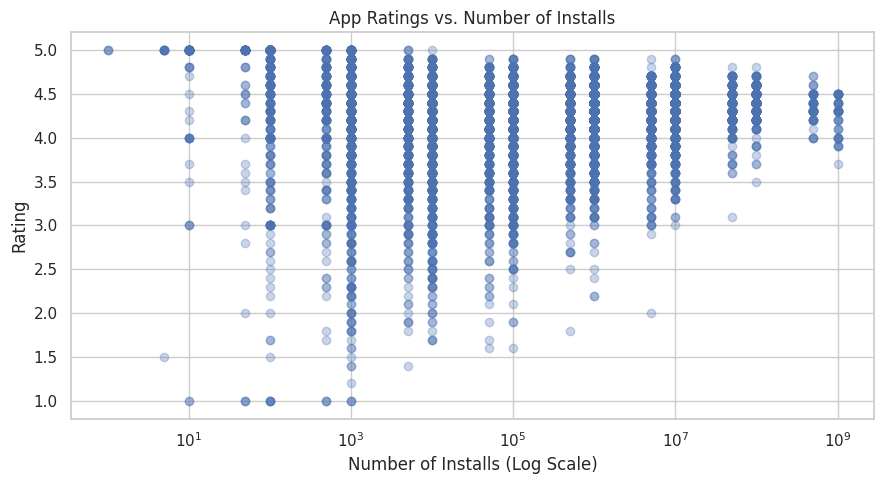

In [66]:
plt.figure(figsize=(9, 5))

plt.scatter(apps["Installs"], apps["Rating"], alpha=0.3)

plt.xscale("log")
plt.title("App Ratings vs. Number of Installs")
plt.xlabel("Number of Installs (Log Scale)")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

In [67]:
#app categories that have the highest average ratings
average_rating_by_category = (apps.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
    .round(2))

print(average_rating_by_category)

Category
EVENTS                 4.44
EDUCATION              4.38
ART_AND_DESIGN         4.36
BOOKS_AND_REFERENCE    4.35
PERSONALIZATION        4.33
PARENTING              4.30
GAME                   4.28
BEAUTY                 4.28
HEALTH_AND_FITNESS     4.26
SOCIAL                 4.25
SHOPPING               4.25
WEATHER                4.24
SPORTS                 4.23
PRODUCTIVITY           4.20
FAMILY                 4.19
AUTO_AND_VEHICLES      4.19
PHOTOGRAPHY            4.18
MEDICAL                4.18
LIBRARIES_AND_DEMO     4.18
HOUSE_AND_HOME         4.16
FOOD_AND_DRINK         4.16
COMICS                 4.16
COMMUNICATION          4.15
ENTERTAINMENT          4.14
NEWS_AND_MAGAZINES     4.13
FINANCE                4.13
BUSINESS               4.10
LIFESTYLE              4.10
TRAVEL_AND_LOCAL       4.09
VIDEO_PLAYERS          4.06
MAPS_AND_NAVIGATION    4.05
TOOLS                  4.05
DATING                 3.97
Name: Rating, dtype: float64


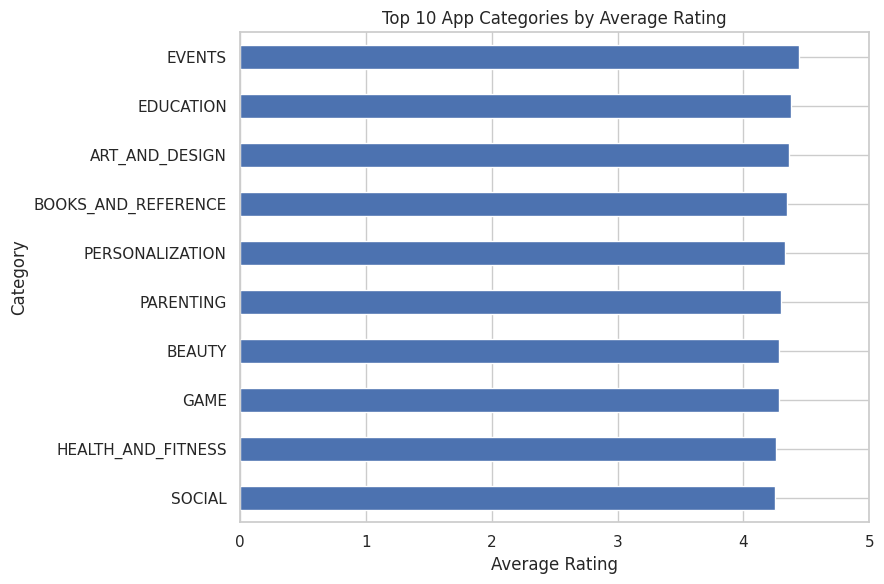

In [68]:
average_rating_by_category.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 10 App Categories by Average Rating",
    xlim=(0, 5))

plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [69]:
#Does app price affect its rating
average_rating_by_type = (apps.groupby("Type")["Rating"]
    .mean()
    .round(2))

print(average_rating_by_type)

Type
Free    4.18
Paid    4.26
Name: Rating, dtype: float64


In [70]:
#How do ratings vary across content-rating categories?
average_rating_by_content = (apps.groupby("Content Rating")["Rating"]
    .mean()
    .sort_values(ascending=False)
    .round(2))

print(average_rating_by_content)

Content Rating
Adults only 18+    4.30
Everyone 10+       4.25
Teen               4.24
Everyone           4.18
Mature 17+         4.12
Unrated            4.10
Name: Rating, dtype: float64


In [71]:
#genres with more than 1 million installs
genre_installs = (apps.groupby("Genres")["Installs"]
    .sum()
    .sort_values(ascending=False))

popular_genres = genre_installs[genre_installs > 1_000_000]

print(popular_genres)

Genres
Communication                  24152276251
Social                         12513867902
Productivity                   12463091369
Tools                          11442771915
Photography                     9721247655
                                  ...     
Art & Design;Creativity            2210000
Simulation;Pretend Play            2110000
Casual;Education                   2010000
Puzzle;Creativity                  1500000
Strategy;Action & Adventure        1100000
Name: Installs, Length: 95, dtype: Int64


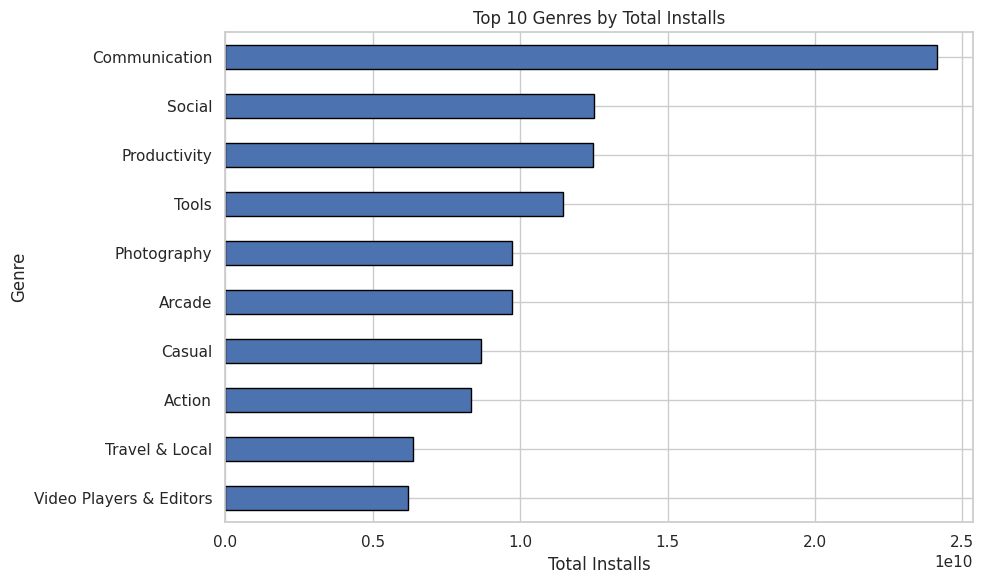

In [72]:
import matplotlib.pyplot as plt

top_10_genres = genre_installs.head(10).sort_values()

top_10_genres.plot(kind="barh", figsize=(10, 6), edgecolor="black")

plt.title("Top 10 Genres by Total Installs")
plt.xlabel("Total Installs")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [73]:
#Relation between app size and installs
size_installs_corr = apps[["Size", "Installs"]].corr().loc["Size", "Installs"]

print("Correlation between app size and installs:", round(size_installs_corr, 4))

Correlation between app size and installs: 0.1689


In [74]:
#10 apps with the highest review counts
top_reviewed_apps = (
    unique_apps.nlargest(10, "Reviews")[["App", "Category", "Reviews", "Rating", "Installs"]]
)

print(top_reviewed_apps.to_string(index=False))

                                               App      Category    Reviews  Rating   Installs
                                          Facebook        SOCIAL 78158306.0     4.1 1000000000
                                WhatsApp Messenger COMMUNICATION 69119316.0     4.4 1000000000
                                         Instagram        SOCIAL 66577446.0     4.5 1000000000
          Messenger – Text and Video Chat for Free COMMUNICATION 56646578.0     4.0 1000000000
                                    Clash of Clans          GAME 44893888.0     4.6  100000000
           Clean Master- Space Cleaner & Antivirus         TOOLS 42916526.0     4.7  500000000
                                    Subway Surfers          GAME 27725352.0     4.5 1000000000
                                           YouTube VIDEO_PLAYERS 25655305.0     4.3 1000000000
Security Master - Antivirus, VPN, AppLock, Booster         TOOLS 24900999.0     4.7  500000000
                                      Clash Royale

In [75]:
#content-rating distribution between free and paid apps
content_type_counts = pd.crosstab(
    apps["Content Rating"],
    apps["Type"])

print(content_type_counts)

Type             Free  Paid
Content Rating             
Adults only 18+     3     0
Everyone         7720   662
Everyone 10+      344    32
Mature 17+        428    19
Teen             1094    52
Unrated             2     0


In [76]:
#five categories having the highest total installs
category_installs = (apps.groupby("Category")["Installs"]
    .sum()
    .sort_values(ascending=False))

print(category_installs.head(5))

Category
GAME             31544024415
COMMUNICATION    24152276251
SOCIAL           12513867902
PRODUCTIVITY     12463091369
TOOLS            11452771915
Name: Installs, dtype: Int64


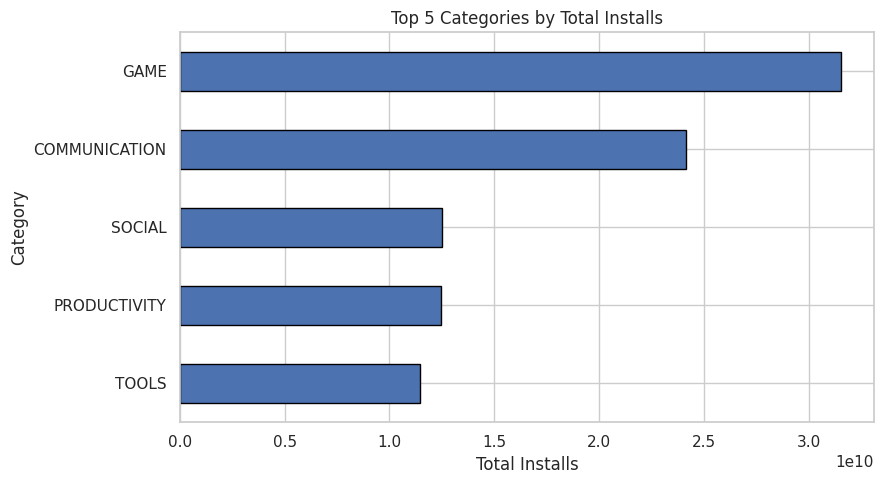

In [77]:
import matplotlib.pyplot as plt

top_5_categories = category_installs.head(5).sort_values()

top_5_categories.plot(kind="barh",
    figsize=(9, 5),
    edgecolor="black")

plt.title("Top 5 Categories by Total Installs")
plt.xlabel("Total Installs")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [78]:
# Count apps by last-update year
apps_by_update_year = (apps["Last Updated"]
    .dt.year
    .value_counts()
    .sort_index())

print(apps_by_update_year)

Last Updated
2010       1
2011      15
2012      26
2013     108
2014     204
2015     454
2016     789
2017    1826
2018    6934
Name: count, dtype: int64


In [79]:
#top 10 highest-rated apps and their reviews and installs
top_rated_apps = (
    unique_apps[unique_apps["Reviews"] >= 100000]
    .sort_values(by=["Rating", "Reviews"],ascending=[False, False])
    .head(10)
    [["App", "Rating", "Reviews", "Installs"]]
)

print(top_rated_apps.to_string(index=False))

                                               App  Rating   Reviews  Installs
                                        JW Library     4.9  922752.0  10000000
                 Six Pack in 30 Days - Abs Workout     4.9  272337.0  10000000
                           Tickets + PDA 2018 Exam     4.9  197136.0   1000000
    Learn Japanese, Korean, Chinese Offline & Free     4.9  133136.0   1000000
Period Tracker - Period Calendar Ovulation Tracker     4.8 4559407.0 100000000
 DU Recorder – Screen Recorder, Video Editor, Live     4.8 2588730.0  50000000
                                          Eternium     4.8 1506783.0  10000000
                       PewDiePie's Tuber Simulator     4.8 1499466.0  10000000
                     Vlogger Go Viral - Tuber Game     4.8 1304467.0  10000000
                      Amino: Communities and Chats     4.8 1264084.0  10000000


In [80]:
#monthly distribution of recorded app-update dates
monthly_updates = (
    apps.dropna(subset=["Last Updated"])
    .groupby(apps["Last Updated"].dt.to_period("M"))
    .size()
)

monthly_updates.index = monthly_updates.index.astype(str)

print(monthly_updates.sort_values(ascending=False).head(10))

Last Updated
2018-07    2653
2018-08    1157
2018-06     966
2018-05     725
2018-03     419
2018-04     415
2018-02     304
2018-01     295
2017-12     250
2017-10     218
dtype: int64


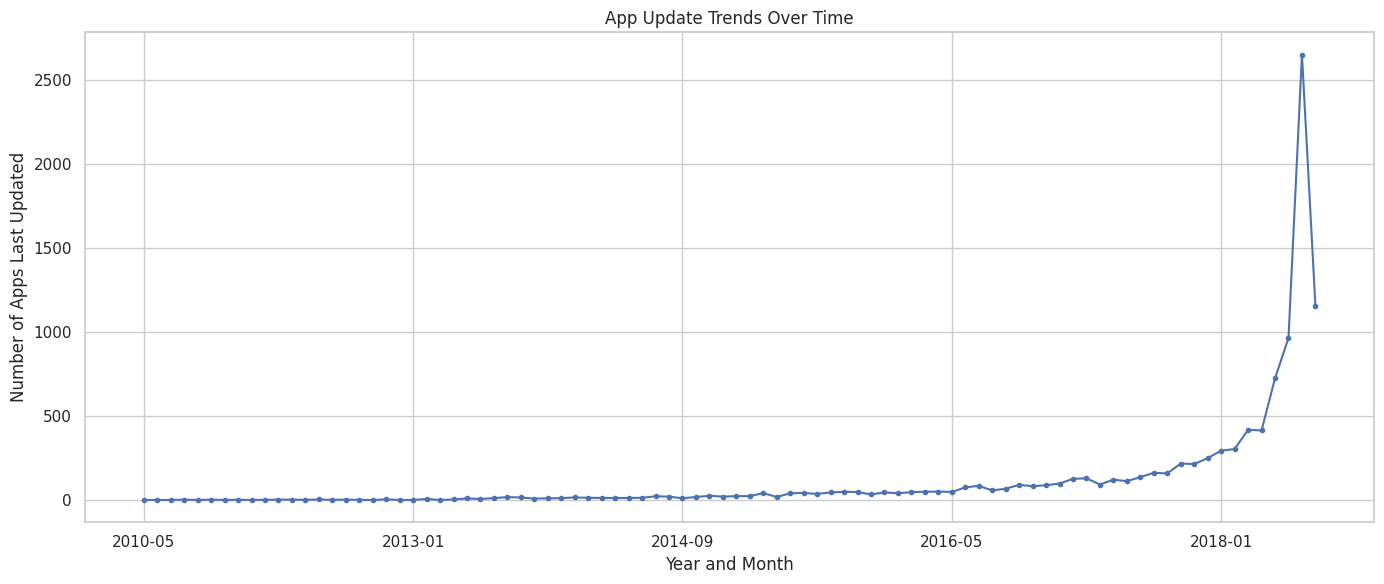

In [81]:
import matplotlib.pyplot as plt

monthly_updates.plot(
    figsize=(14, 6),
    kind="line",
    marker="o",
    markersize=3
)

plt.title("App Update Trends Over Time")
plt.xlabel("Year and Month")
plt.ylabel("Number of Apps Last Updated")
plt.tight_layout()
plt.show()

In [82]:
# Count recorded app-update dates by calendar month
updates_by_month = (
    apps.dropna(subset=["Last Updated"])
    .groupby(apps["Last Updated"].dt.month)
    .size()
)

updates_by_month.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(updates_by_month.sort_values(ascending=False))

Jul    2950
Aug    1466
Jun    1226
May     962
Mar     656
Apr     600
Feb     527
Jan     480
Dec     421
Oct     387
Nov     374
Sep     308
dtype: int64


In [83]:
# Count recorded last-update dates by year and calendar month
year_month_updates = (
    apps.dropna(subset=["Last Updated"])
    .groupby([
        apps["Last Updated"].dt.year,
        apps["Last Updated"].dt.month
    ])
    .size()
    .unstack(fill_value=0)
)

# Display counts for every year and month
year_month_updates.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(year_month_updates)

              Jan  Feb  Mar  Apr  May  Jun   Jul   Aug  Sep  Oct  Nov  Dec
Last Updated                                                              
2010            0    0    0    0    1    0     0     0    0    0    0    0
2011            1    0    1    3    1    3     1     0    2    1    0    2
2012            3    3    0    2    0    4     2     3    2    1    5    1
2013            1    7    1    4   10    7    12    18   16    9   11   12
2014           16   14   13   13   13   14    23    21   11   19   26   21
2015           24   24   42   19   41   43    37    46   50   48   34   46
2016           41   48   50   51   49   76    85    58   68   91   83   89
2017           99  127  130   93  122  113   137   163  159  218  215  250
2018          295  304  419  415  725  966  2653  1157    0    0    0    0


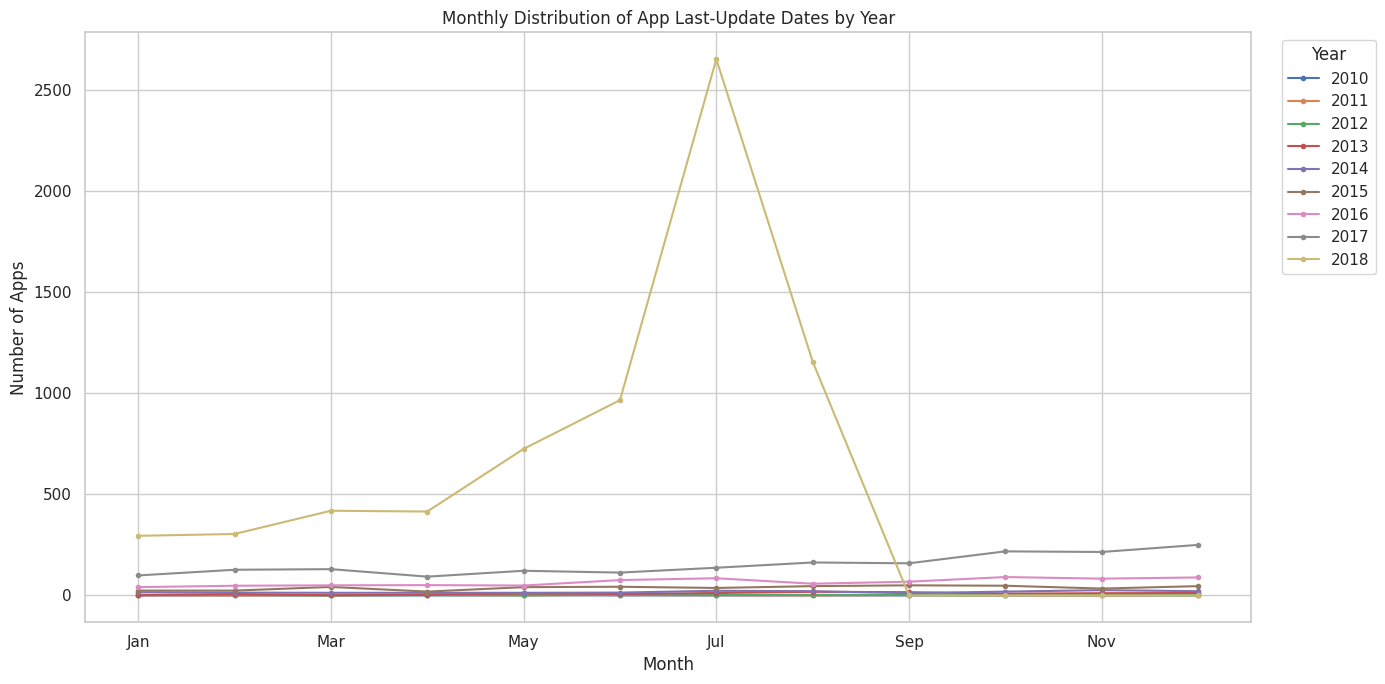

In [84]:
import matplotlib.pyplot as plt

year_month_updates.T.plot(
    figsize=(14, 7),
    marker="o",
    markersize=3
)

plt.title("Monthly Distribution of App Last-Update Dates by Year")
plt.xlabel("Month")
plt.ylabel("Number of Apps")
plt.xticks(rotation=0)
plt.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [85]:
#install-range categories
apps["Install Range"] = pd.cut(
    apps["Installs"],
    bins=[-1, 1000, 10000, 100000, 1000000, 10000000, 100000000, float("inf")],
    labels=["Up to 1K",
        "1K–10K",
        "10K–100K",
        "100K–1M",
        "1M–10M",
        "10M–100M",
        "100M+"]
)

#average rating for each install range
rating_by_installs = (
    apps.groupby("Install Range", observed=False)["Rating"]
    .agg(["mean", "count"])
    .round(2)
)

print(rating_by_installs)

               mean  count
Install Range             
Up to 1K       4.20   1337
1K–10K         4.03   1415
10K–100K       4.09   1572
100K–1M        4.21   2002
1M–10M         4.29   1815
10M–100M       4.38    641
100M+          4.31    110


In [86]:
#genres having the highest average ratings
genre_ratings = (
    apps.groupby("Genres")["Rating"]
    .agg(["mean", "count"])
    .query("count >= 20")
    .sort_values("mean", ascending=False)
    .round(2)
)

print(genre_ratings.head(15))

                           mean  count
Genres                                
Events                     4.44     45
Word                       4.40     27
Puzzle                     4.39    117
Art & Design               4.36     56
Education;Education        4.35     44
Books & Reference          4.35    177
Parenting                  4.34     40
Personalization            4.33    310
Arcade                     4.30    205
Racing;Action & Adventure  4.30     20
Education                  4.30    446
Board                      4.29     41
Casino                     4.29     37
Action                     4.28    349
Beauty                     4.28     42
